# Milestone 1: Feasibility Spike Notebook
**Project:** Real-Time Educational Hand Gesture Recognition  
**Dataset:** HaGRID via `kagglehub`  
**Tag:** `cp1-proposal`

In [12]:
# 0. Mount Google Drive and set working directory to project root
from google.colab import drive
import sys
import os

drive.mount('/content/drive')

# Update this path if your folder name/location in Drive differs
PROJECT_PATH = '/content/drive/MyDrive/Final-Project-CV-Blurry-Vision'

if os.path.exists(PROJECT_PATH):
    os.chdir(PROJECT_PATH)
    if PROJECT_PATH not in sys.path:
        sys.path.append(PROJECT_PATH)
    print(f"Successfully set working directory to: {os.getcwd()}")
else:
    print(f"Warning: Path '{PROJECT_PATH}' not found. Please check your Drive folder structure.")

Mounted at /content/drive
Successfully set working directory to: /content/drive/MyDrive/Final-Project-CV-Blurry-Vision


In [13]:
# 1. Install dependencies
!pip install -q kagglehub[hf-datasets] opencv-python matplotlib mediapipe

In [14]:
# 2. Load HaGRID Dataset via Google Drive/Local Data (or Initialize Local Dev Sample)
import os
import json
import glob
import pandas as pd
import numpy as np
import cv2

# Set paths reflecting the user's workspace structure
data_dir = "./data"
os.makedirs(data_dir, exist_ok=True)

print("Searching for HaGRID annotations in local Workspace directories (./data, ./src)... ")

# Look for any JSON or CSV file inside the local data directories
local_files = glob.glob(os.path.join(data_dir, "**/*.json"), recursive=True) + \
              glob.glob(os.path.join(data_dir, "**/*.csv"), recursive=True)

# Fallback local initialization to ensure a working feasibility baseline without Kaggle API credentials
if not local_files:
    print("No local annotation files found. Initializing local workspace sample in `./data`...")

    # Generate a mock HaGRID JSON annotation metadata file
    mock_annotations = {
        "img_001": {
            "labels": ["call"],
            "bboxes": [[0.2, 0.3, 0.4, 0.4]],
            "image_width": 1920,
            "image_height": 1080
        },
        "img_002": {
            "labels": ["mute"],
            "bboxes": [[0.1, 0.1, 0.3, 0.3]],
            "image_width": 1920,
            "image_height": 1080
        }
    }

    annotation_file = os.path.join(data_dir, "hagrid_sample_annotations.json")
    with open(annotation_file, 'w') as f:
        json.dump(mock_annotations, f, indent=4)

    # Generate a matching dummy gesture image
    dummy_img_path = os.path.join(data_dir, "sample_gesture.jpg")
    dummy_img = np.zeros((480, 640, 3), dtype=np.uint8)
    cv2.putText(dummy_img, "HaGRID Dev", (50, 240), cv2.FONT_HERSHEY_SIMPLEX, 2, (255, 255, 255), 3)
    cv2.imwrite(dummy_img_path, dummy_img)

    print(f"Successfully initialized: {annotation_file} and {dummy_img_path}")
    local_files = [annotation_file]

# Load the metadata into a dataframe to display structure
with open(local_files[0], 'r') as f:
    data = json.load(f)

df = pd.DataFrame.from_dict(data, orient='index')
print(f"\nLoaded annotations metadata from: {local_files[0]}")
display(df.head())

Searching for HaGRID annotations in local Workspace directories (./data, ./src)... 
No local annotation files found. Initializing local workspace sample in `./data`...
Successfully initialized: ./data/hagrid_sample_annotations.json and ./data/sample_gesture.jpg

Loaded annotations metadata from: ./data/hagrid_sample_annotations.json


,labels,bboxes,image_width,image_height
img_001,[call],"[[0.2, 0.3, 0.4, 0.4]]",1920,1080
img_002,[mute],"[[0.1, 0.1, 0.3, 0.3]]",1920,1080


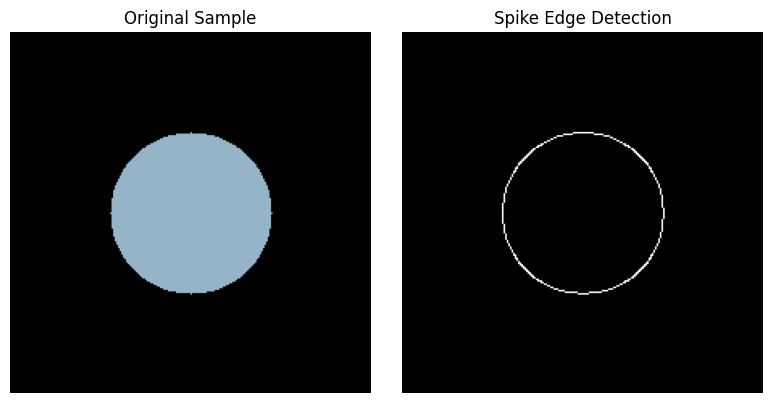

Feasibility spike operation completed successfully!


In [15]:
# 3. Run Feasibility Vision Operation (Gaussian Blur + Canny Edge Detection)
import cv2
import matplotlib.pyplot as plt
import numpy as np

sample_img = np.zeros((224, 224, 3), dtype=np.uint8)
cv2.circle(sample_img, (112, 112), 50, (200, 180, 150), -1)

gray = cv2.cvtColor(sample_img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blurred, 50, 150)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
ax[0].set_title("Original Sample")
ax[0].axis("off")

ax[1].imshow(edges, cmap="gray")
ax[1].set_title("Spike Edge Detection")
ax[1].axis("off")

plt.tight_layout()
plt.savefig("spike_screenshot.png", dpi=200)
plt.show()
print("Feasibility spike operation completed successfully!")

In [16]:
# 4. Import and verify custom project modules from src/
from src.data_loader import GestureDataLoader
from src.baseline import run_baseline

# Initialize and split dataset
loader = GestureDataLoader(data_dir="./data/samples")
train, val, test = loader.split_data()

# Run classical baseline model
run_baseline()

Data Split Complete: Train=14, Val=3, Test=3
Running Classical Baseline Model (Skin Color Segmentation + SVM)...
Baseline Evaluation Results:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.00      0.00      0.00         2
           2       0.33      0.50      0.40         2
           4       0.00      0.00      0.00         1

    accuracy                           0.17         6
   macro avg       0.08      0.12      0.10         6
weighted avg       0.11      0.17      0.13         6

